# CS781 Phase 2. Decoder full fine-tuning for legal NER

I fine-tuned the Phase 1 causal decoder end to end and added a residual BiLSTM, a BIO tagging head and two character-boundary heads. The BiLSTM adds context from both directions within each window while the Transformer retains its causal mask. Document-level Viterbi uses fixed legal BIO transitions.

| Run | Best epoch | Validation strict macro F1 | CodaBench strict macro F1 | Submission ID |
| --- | ---: | ---: | ---: | ---: |
| `decoder_ner_bilstm_full_003` | 50 | 0.440496 | 0.4118 | 974407 |

The earlier BiLSTM run reached 0.4256 on the same split. This run changed the backbone learning rate and head regularization together, so the comparison measures their combined effect.


## 1. Inputs and environment

1. Start a Kaggle notebook with two T4 GPUs. Keep Kaggle's PyTorch installation.
2. Attach `prep_002_mixed16k` with `tokenizer_state.pkl` and `cache_manifest.json`, and the original
   [Phase 1 run](../phase1/phase1_decoder_training.ipynb) `decoder_004_mixed217m` with `best_model.pt` and its source metadata.
   Set `PREP_INPUT` and `DECODER_INPUT` when automatic discovery is ambiguous.
3. Attach `Phase_2_LNER` or `phase2_lner_data.zip` through `PHASE2_INPUT`, or enable Internet
   and provide the Kaggle secret `HF_TOKEN` for the pinned dataset download.
4. Leave `INIT_MODE = "phase1"` to initialize the task heads and optimizer afresh. Set `RESUME_INPUT` only to resume this NER run from its saved files.


In [1]:
%pip install -q huggingface_hub


Note: you may need to restart the kernel to use updated packages.


In [2]:
import gc
import importlib.metadata
import hashlib
import json
import math
import os
import pickle
import random
import shutil
import sys
import time
from dataclasses import asdict
from pathlib import Path

import numpy as np
import torch

PREPARATION_ID = "prep_002_mixed16k"
PHASE1_RUN_ID = "decoder_004_mixed217m"
RUN_ID = "decoder_ner_bilstm_full_003"
INIT_MODE = "phase1"  # Always initialize this new experiment from the original LM

# None finds the matching folder automatically. Set exact paths if there are multiple matches.
PREP_INPUT = None         # Folder containing tokenizer_state.pkl and cache_manifest.json
DECODER_INPUT = None      # Decoder run folder, or its best_model.pt
PHASE2_INPUT = None       # Phase_2_LNER folder, parent folder, or phase2_lner_data.zip
RESUME_INPUT = None       # Previous NER run folder or NER backup ZIP for a fresh session

HF_DATASET_REVISION = "89edba6a44d6bb9593fd13b6895b5cd3b06eb82e"
ROOT = Path("/kaggle/working/cs781_phase2")
SRC = Path("/kaggle/working/cs781_phase2_regularized_src")
RUN_DIR = ROOT / "runs" / RUN_ID
ROOT.mkdir(parents=True, exist_ok=True)
SRC.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_TOKENS = 1024
WINDOW_OVERLAP = 256
VALIDATION_FRACTION = 0.20
SETTINGS = {
    "seed": 42,
    "epochs": 50,                 # maximum epochs in this NEW stage
    "minimum_epochs": 10,
    "patience": 8,
    "early_stop_min_delta": 0.001,
    "microbatch_size": 4,
    "accumulation_steps": 4,
    "prediction_batch_size": 4,
    "backbone_lr": 3e-6,
    "head_lr": 5e-5,              # existing BIO and character heads
    "context_lr": 1e-4,           # new BiLSTM branch
    "warmup_epochs": 1,
    "lr_factor": 0.5,
    "lr_patience": 3,
    "minimum_lr_fraction": 0.2,
    "weight_decay": 0.05,
    "gradient_clip": 1.0,
    "boundary_loss_weight": 0.5,
    "class_weighting": "mild_entity",  # or none; training counts only
    "decode_mode": "viterbi",          # or argmax in a separate experiment
    "bilstm_hidden_size": 128,
    "head_dropout": 0.3,
    "tag_label_smoothing": 0.05,  # BIO loss only; character-boundary loss stays hard
    "gradient_checkpointing": True,
    "save_every_minutes": 10,
    "log_every": 10,
    "max_run_hours": 9.0,
    "minimum_free_gb": 4.0,
}
GENERATE_TEST_PREDICTIONS = True
MAKE_RESUME_BACKUP = True
REFERENCE_STRICT_MACRO_F1 = 0.4255551245981935

if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
    raise RuntimeError("Select GPU T4 x2 in Kaggle before running this notebook")
device = torch.device("cuda:0")
random.seed(SETTINGS["seed"])
np.random.seed(SETTINGS["seed"])
torch.manual_seed(SETTINGS["seed"])
torch.cuda.manual_seed_all(SETTINGS["seed"])

print("PyTorch:", torch.__version__)
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"GPU {i}: {p.name}, {p.total_memory / 2**30:.1f} GiB")
print("Effective batch:", SETTINGS["microbatch_size"] * SETTINGS["accumulation_steps"], "windows")
print("Run folder:", RUN_DIR)

assert INIT_MODE == "phase1"
assert 0 <= SETTINGS["tag_label_smoothing"] < 1


PyTorch: 2.11.0+cu128
GPU 0: Tesla T4, 14.6 GiB
GPU 1: Tesla T4, 14.6 GiB
Effective batch: 16 windows
Run folder: /kaggle/working/cs781_phase2/runs/decoder_ner_bilstm_full_003


## 2. Model and data implementation

The cells below write the matching Phase 1 backbone and tokenizer, the offset and window
helpers, the NER model and trainer, and the course evaluator into the working directory.
The preparation and checkpoint checks use the saved source hashes.


In [3]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path


Writing /kaggle/working/cs781_phase2_regularized_src/phase1_utils.py


In [4]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Writing /kaggle/working/cs781_phase2_regularized_src/a1_tokenizer.py


In [5]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/phase1_decoder.py
"""Phase 1 decoder, adapted from completed Assignment 3 Q1."""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class LMConfig:
    vocab_size: int = 16000
    d_model: int = 1024
    n_layers: int = 16
    n_heads: int = 16
    d_ff: int = 4096
    max_seq_len: int = 2560
    dropout: float = 0.1
    norm_first: bool = True
    attention_impl: str = "sdpa"
    attention_scale: float = None
    embedding_scale: float = 32.0


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, max_seq_len, dropout=0.0,
                 attention_scale=None, attention_impl="sdpa"):
        super().__init__()
        assert d_model % n_heads == 0
        if attention_impl not in ("manual", "sdpa"):
            raise ValueError("attention_impl must be manual or sdpa")
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.attention_scale = 1.0 / math.sqrt(self.d_head) if attention_scale is None else float(attention_scale)
        self.attention_impl = attention_impl
        self.q_proj = nn.Linear(d_model, d_model, bias=False)
        self.k_proj = nn.Linear(d_model, d_model, bias=False)
        self.v_proj = nn.Linear(d_model, d_model, bias=False)
        self.out_proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)
        if attention_impl == "manual":
            self.register_buffer("causal_mask", torch.tril(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool)),
                                 persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        if self.attention_impl == "manual":
            scores = (q @ k.transpose(-2, -1)) * self.attention_scale
            scores = scores.masked_fill(~self.causal_mask[:T, :T], float("-inf"))
            weights = self.attn_dropout(torch.softmax(scores, dim=-1))
            out = weights @ v
        else:
            out = F.scaled_dot_product_attention(
                q, k, v, is_causal=True, scale=self.attention_scale,
                dropout_p=self.attn_dropout.p if self.training else 0.0,
            )
        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_dropout(self.out_proj(out))


def sinusoidal_positional_encoding(max_len, d_model):
    position = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(position * frequency)
    pe[:, 1::2] = torch.cos(position * frequency)
    return pe


class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(),
                                 nn.Linear(d_ff, d_model), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm_first = cfg.norm_first
        self.ln1 = nn.LayerNorm(cfg.d_model)
        self.attn = CausalSelfAttention(cfg.d_model, cfg.n_heads, cfg.max_seq_len, cfg.dropout,
                                      cfg.attention_scale, cfg.attention_impl)
        self.ln2 = nn.LayerNorm(cfg.d_model)
        self.ffn = FeedForward(cfg.d_model, cfg.d_ff, cfg.dropout)

    def forward(self, x):
        if self.norm_first:
            x = x + self.attn(self.ln1(x))
            x = x + self.ffn(self.ln2(x))
        else:
            x = self.ln1(x + self.attn(x))
            x = self.ln2(x + self.ffn(x))
        return x


class DecoderLM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", sinusoidal_positional_encoding(cfg.max_seq_len, cfg.d_model),
                             persistent=False)
        self.blocks = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.ln_f = nn.LayerNorm(cfg.d_model)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

        # parameters() counts the tied matrix once.
        for parameter in self.parameters():
            if parameter.ndim > 1:
                nn.init.xavier_uniform_(parameter)
        for module in self.modules():
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, idx, last_positions=None):
        B, T = idx.shape
        if T > self.cfg.max_seq_len:
            raise ValueError("Input exceeds the configured context length")
        x = self.tok_emb(idx) * self.cfg.embedding_scale + self.pos_emb[:T].unsqueeze(0)
        for block in self.blocks:
            x = block(x)
        x = self.ln_f(x)
        if last_positions is not None:
            x = x[torch.arange(B, device=idx.device), last_positions]
        return self.head(x)


class ModelWithLoss(nn.Module):
    """Compute loss on each GPU before DataParallel gathers the small outputs."""
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm = lm
        self.use_amp = use_amp

    def forward(self, x, y):
        # Enter autocast in each worker thread; do not move the model to half().
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits = self.lm(x)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), y.reshape(-1))
        return loss.unsqueeze(0)


Writing /kaggle/working/cs781_phase2_regularized_src/phase1_decoder.py


In [6]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_data.py
"""Shared legal NER alignment, windows, and exact span decoding."""
import bisect
import hashlib
import json
import pickle
import re
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np

IGNORE = -100


def read_json(path):
    def pairs(items):
        result = {}
        for key, value in items:
            if key in result:
                raise ValueError(f"Duplicate JSON key: {key}")
            result[key] = value
        return result
    def reject(value):
        raise ValueError(f"Invalid JSON constant: {value}")
    return json.loads(Path(path).read_text(encoding="utf-8"),
                      object_pairs_hook=pairs, parse_constant=reject)


def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(2**20), b""):
            h.update(chunk)
    return h.hexdigest()


def write_json(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(data, indent=2, ensure_ascii=False,
                                   allow_nan=False), encoding="utf-8")
    temporary.replace(path)


class OffsetTokenizer:
    """Same byte BPE as Phase 1, retaining offsets in the unchanged string."""
    def __init__(self, state_path, manifest_path):
        self.manifest = read_json(manifest_path)
        if file_hash(state_path) != self.manifest["tokenizer_state_sha256"]:
            raise ValueError("Tokenizer bytes do not match the preparation manifest")
        with open(state_path, "rb") as f:
            saved = pickle.load(f)
        if saved["signature"] != self.manifest["tokenizer_signature"]:
            raise ValueError("Tokenizer signatures differ")
        self.signature = saved["signature"]
        self.state = saved["state"]
        self.vocab = self.state["vocab"]
        self.merges = self.state["merges"]
        self.boundary_id = self.state["boundary_id"]
        self.max_chars = max(len(piece) for piece in self.vocab)
        self.pad_id = 0

    @lru_cache(maxsize=100000)
    def encode_piece(self, piece):
        symbols = [byte + 4 for byte in piece.encode("utf-8")] + [self.boundary_id]
        while len(symbols) > 1:
            candidates = [(self.merges[(a, b)], (a, b))
                          for a, b in zip(symbols, symbols[1:])
                          if (a, b) in self.merges]
            if not candidates:
                break
            new_id, pair = min(candidates)
            merged, j = [], 0
            while j < len(symbols):
                if j + 1 < len(symbols) and (symbols[j], symbols[j+1]) == pair:
                    merged.append(new_id)
                    j += 2
                else:
                    merged.append(symbols[j])
                    j += 1
            symbols = merged
        return tuple(symbols)

    def encode(self, text):
        ids, offsets, exact_edges = [], [], []
        for match in re.finditer(r"\S+|\s+", text):
            piece = match.group()
            byte_edges = [0]
            for character in piece:
                byte_edges.append(byte_edges[-1] + len(character.encode("utf-8")))
            byte_to_char = {byte: char for char, byte in enumerate(byte_edges)}
            position = 0
            for token_id in self.encode_piece(piece):
                end = position + len(self.vocab[token_id])
                if end == position:
                    # A standalone end-of-piece marker has no character target.
                    offset = (match.start() + bisect.bisect_left(byte_edges, position),) * 2
                else:
                    offset = (match.start() + bisect.bisect_right(byte_edges, position)-1,
                              match.start() + bisect.bisect_left(byte_edges, end))
                ids.append(token_id)
                offsets.append(offset)
                exact_edges.append((position in byte_to_char, end in byte_to_char))
                position = end
            if position != byte_edges[-1]:
                raise AssertionError("BPE bytes did not cover the original piece")
        if b"".join(self.vocab[token_id] for token_id in ids).decode("utf-8") != text:
            raise AssertionError("Tokenization changed the document")
        return {"ids": np.asarray(ids, dtype=np.int64),
                "offsets": np.asarray(offsets, dtype=np.int32).reshape(-1, 2),
                "exact_edges": np.asarray(exact_edges, dtype=bool).reshape(-1, 2)}


def load_folds(root):
    root = Path(root)
    labels = [line.strip() for line in (root/"Train/labels.txt").read_text().splitlines()
              if line.strip()]
    if len(labels) != 12 or len(set(labels)) != 12:
        raise ValueError("The official label vocabulary must contain 12 unique labels")
    texts, gold, fold_ids = {}, {}, {}
    for fold in (1, 2):
        part = read_json(root/f"Train/fold{fold}-text.json")
        truth = read_json(root/f"Train/fold{fold}-gold.json")
        if set(part) != set(truth) or set(part) & set(texts):
            raise ValueError("Training document IDs are missing or duplicated across folds")
        if any(not isinstance(t, str) or not t for t in part.values()):
            raise ValueError("Training documents must be non-empty strings")
        fold_ids[fold] = sorted(part)
        texts.update(part)
        gold.update(truth)
    test = read_json(root/"Test/fold3-text.json")
    if set(test) & set(texts):
        raise ValueError("Train/test document IDs overlap")
    if any(not isinstance(t, str) for t in test.values()):
        raise ValueError("Test documents must be strings")
    # The official fold includes an empty document. Preserve its ID and predict [].
    return texts, gold, test, labels, fold_ids


def document_split(texts, gold, folds, labels, seed=42, fraction=0.2):
    # Select whole documents before windowing. No model scores enter this split.
    groups = []
    if len({hashlib.sha256(t.encode()).hexdigest() for t in texts.values()}) != len(texts):
        raise ValueError("Duplicate document texts exist; group them before splitting")
    for ids in folds.values():
        hashes = {}
        for did in ids:
            digest = hashlib.sha256(texts[did].encode()).hexdigest()
            hashes.setdefault(digest, []).append(did)
        groups.append(list(hashes.values()))
    if sum(len(g) for g in groups) != len(texts):
        raise ValueError("Duplicate training texts exist; group them across folds before splitting")
    for attempt in range(1000):
        rng = np.random.default_rng(seed + attempt)
        val = []
        for group in groups:
            order = rng.permutation(len(group))
            count = max(1, round(len(group) * fraction))
            val.extend(did for i in order[:count] for did in group[int(i)])
        train = sorted(set(texts)-set(val))
        val = sorted(val)
        present = lambda ids: {entity[2] for did in ids for entity in gold[did]}
        if present(train) == set(labels) == present(val):
            return {"train_ids": train, "validation_ids": val,
                    "seed": seed, "selection_attempt": attempt,
                    "validation_fraction": fraction}
    raise ValueError("Could not obtain a split with every label in train and validation")


def decode_spans(text, document, tag_ids, starts, ends, tag_names):
    offsets = document["offsets"]
    result, active = [], None
    def finish():
        nonlocal active
        if active is not None:
            first, last, label = active
            a = int(offsets[first, 0]) + int(starts[first])
            b = int(offsets[last, 0]) + int(ends[last])
            if 0 <= a < b <= len(text):
                result.append((a, b, label))
        active = None
    for i, (a, b) in enumerate(offsets):
        if a == b:
            continue
        name = tag_names[int(tag_ids[i])]
        if name == "O":
            finish()
            continue
        prefix, label = name.split("-", 1)
        if prefix == "B" or active is None or active[2] != label:
            finish()
            active = [i, i, label]
        else:
            active[1] = i
    finish()
    return [list(span) for span in sorted(set(result))]


def prepare_documents(texts, gold, tokenizer, labels):
    tag_names = ["O"] + [tag for label in labels for tag in ("B-"+label, "I-"+label)]
    tag_to_id = {name: i for i, name in enumerate(tag_names)}
    documents, counts, examples = {}, Counter(), []
    for did, text in texts.items():
        doc = tokenizer.encode(text)
        n = len(doc["ids"])
        a, b = doc["offsets"].T
        content = b > a
        tags = np.where(content, 0, IGNORE).astype(np.int64)
        start_y = np.full(n, IGNORE, dtype=np.int64)
        end_y = np.full(n, IGNORE, dtype=np.int64)
        spans = sorted(gold.get(did, []), key=lambda e: (e[0], e[1], e[2]))
        previous_end = -1
        for entity in spans:
            begin, end, label = entity[:3]
            if (type(begin) is not int or type(end) is not int or
                    not 0 <= begin < end <= len(text) or label not in labels):
                raise ValueError(f"Invalid gold entity in {did}: {entity}")
            if len(entity) == 4 and text[begin:end] != entity[3]:
                raise ValueError(f"Gold entity text/offset mismatch in {did}")
            if begin < previous_end:
                raise ValueError(f"Overlapping gold entities in {did}; one BIO sequence cannot encode them")
            previous_end = end
            positions = np.flatnonzero(content & (b > begin) & (a < end))
            if not len(positions) or np.any(tags[positions] != 0):
                raise ValueError(f"Two entities share a BPE prediction unit in {did}: {entity}")
            first, last = int(positions[0]), int(positions[-1])
            tags[positions] = tag_to_id["I-"+label]
            tags[first] = tag_to_id["B-"+label]
            start_y[first] = begin - int(a[first])
            end_y[last] = end - int(a[last])
            if not (0 <= start_y[first] < b[first]-a[first] and
                    1 <= end_y[last] <= b[last]-a[last]):
                raise AssertionError("Invalid intra-token boundary target")
            counts[label] += 1
            if (a[first] != begin or b[last] != end or
                    not doc["exact_edges"][first, 0] or not doc["exact_edges"][last, 1]):
                counts["boundary_refinement_needed"] += 1
                if len(examples) < 10:
                    examples.append({"document_id": did, "gold": entity,
                                     "whole_token_text": text[int(a[first]):int(b[last])]})
        doc.update(tags=tags, start_y=start_y, end_y=end_y)
        if spans:
            # Verify representability with the same decoder used at inference.
            start_oracle = np.where(start_y == IGNORE, 0, start_y)
            end_oracle = np.where(end_y == IGNORE, b-a, end_y)
            predicted = decode_spans(text, doc, np.maximum(tags, 0),
                                     start_oracle, end_oracle, tag_names)
            if {tuple(e[:3]) for e in spans} != {tuple(e) for e in predicted}:
                raise AssertionError(f"Gold-to-tags-to-spans round trip failed for {did}")
        documents[did] = doc
    report = {"documents": len(texts), "tokens": sum(len(d["ids"]) for d in documents.values()),
              "entities": sum(counts[label] for label in labels),
              "label_counts": {label: counts[label] for label in labels},
              "boundary_refinement_needed": counts["boundary_refinement_needed"],
              "examples": examples, "oracle_roundtrip": "passed"}
    return documents, tag_names, report


def make_windows(documents, ids, window_size=512, overlap=128):
    if not 0 <= overlap < window_size:
        raise ValueError("Overlap must be smaller than the window")
    windows = []
    for did in ids:
        n = len(documents[did]["ids"])
        starts = list(range(0, n, window_size-overlap))
        owner, quality = np.zeros(n, dtype=np.int32), np.full(n, -1, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            positions = np.arange(start, stop)
            score = np.minimum(positions-start, stop-1-positions)
            choose = score > quality[start:stop]
            owner[start:stop][choose] = wi
            quality[start:stop][choose] = score[choose]
        seen = np.zeros(n, dtype=np.int32)
        for wi, start in enumerate(starts):
            stop = min(start+window_size, n)
            mask = owner[start:stop] == wi
            if not mask.any():
                continue
            seen[start:stop] += mask.astype(np.int32)
            windows.append({"document_id": did, "start": start, "stop": stop,
                            "owner": mask})
        if not np.all(seen == 1):
            raise AssertionError("Window ownership must cover each position exactly once")
    return windows


def strict_metrics(gold, predictions, labels):
    if set(gold) != set(predictions):
        raise ValueError("Prediction IDs do not match the gold IDs")
    stats = {label: [0, 0, 0] for label in labels}
    for did in gold:
        g = {tuple(e[:3]) for e in gold[did]}
        p = {tuple(e[:3]) for e in predictions[did]}
        if len(p) != len(predictions[did]):
            raise ValueError("Duplicate predicted spans")
        for label in labels:
            gs, ps = {e for e in g if e[2] == label}, {e for e in p if e[2] == label}
            for i, value in enumerate((len(gs & ps), len(ps-gs), len(gs-ps))):
                stats[label][i] += value
    per_label = {}
    for label, (tp, fp, fn) in stats.items():
        precision = tp/(tp+fp) if tp+fp else 0.0
        recall = tp/(tp+fn) if tp+fn else 0.0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
        per_label[label] = dict(precision=precision, recall=recall, f1=f1,
                                true_positive=tp, false_positive=fp, false_negative=fn)
    return {"strict_macro_f1": float(np.mean([v["f1"] for v in per_label.values()])),
            "strict_macro_precision": float(np.mean([v["precision"] for v in per_label.values()])),
            "strict_macro_recall": float(np.mean([v["recall"] for v in per_label.values()])),
            "per_label": per_label}


Writing /kaggle/working/cs781_phase2_regularized_src/lner_data.py


In [7]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_model.py
"""The Phase 1 causal decoder with BIO and character-boundary heads."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint


class DecoderNER(nn.Module):
    def __init__(self, lm, tag_count, max_chars, gradient_checkpointing=True):
        super().__init__()
        self.cfg = lm.cfg
        self.tok_emb = lm.tok_emb
        self.blocks = lm.blocks
        self.ln_f = lm.ln_f
        self.register_buffer("pos_emb", lm.pos_emb, persistent=False)
        self.dropout = nn.Dropout(lm.cfg.dropout)
        self.tag_head = nn.Linear(lm.cfg.d_model, tag_count)
        self.start_head = nn.Linear(lm.cfg.d_model, max_chars+1)
        self.end_head = nn.Linear(lm.cfg.d_model, max_chars+1)
        self.gradient_checkpointing = gradient_checkpointing
        self.max_chars = max_chars
        # The tied LM vocabulary head is unused; the shared embedding remains trainable.
        for head in (self.tag_head, self.start_head, self.end_head):
            nn.init.normal_(head.weight, std=0.02)
            nn.init.zeros_(head.bias)

    def forward(self, ids, char_lengths, targets=None,
                start_targets=None, end_targets=None, tag_weights=None):
        # Autocast must also be entered inside each DataParallel worker thread.
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            if ids.shape[1] > self.cfg.max_seq_len:
                raise ValueError("Window exceeds the pretrained positional context")
            x = self.tok_emb(ids) * self.cfg.embedding_scale
            x = x + self.pos_emb[:ids.shape[1]].unsqueeze(0)
            for block in self.blocks:
                if self.training and self.gradient_checkpointing:
                    x = checkpoint(block, x, use_reentrant=False, preserve_rng_state=True)
                else:
                    x = block(x)
            x = self.dropout(self.ln_f(x))
            tags, starts, ends = self.tag_head(x), self.start_head(x), self.end_head(x)
            choices = torch.arange(self.max_chars+1, device=ids.device).view(1, 1, -1)
            starts = starts.masked_fill(choices >= char_lengths.unsqueeze(-1), -10000.0)
            ends = ends.masked_fill((choices < 1) | (choices > char_lengths.unsqueeze(-1)), -10000.0)
            if targets is None:
                return tags, starts, ends
            tag_weights = getattr(self, "training_tag_weights", tag_weights)
            tag_loss = F.cross_entropy(tags.float().transpose(1, 2), targets,
                                       weight=tag_weights, ignore_index=-100, reduction="sum")
            start_loss = F.cross_entropy(starts.float().transpose(1, 2), start_targets,
                                         ignore_index=-100, reduction="sum")
            end_loss = F.cross_entropy(ends.float().transpose(1, 2), end_targets,
                                       ignore_index=-100, reduction="sum")
            # Gather only three scalars per GPU for training.
            return torch.stack((tag_loss, start_loss, end_loss)).unsqueeze(0)


Writing /kaggle/working/cs781_phase2_regularized_src/lner_model.py


In [8]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_train.py
"""Training, exact document validation, and resumable checkpoints."""
import gc
import math
import pickle
import random
import shutil
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

from lner_data import IGNORE, decode_spans, file_hash, strict_metrics, write_json


def collate(documents, windows, pad_id=0, labelled=True):
    size = max(w["stop"]-w["start"] for w in windows)
    shape = (len(windows), size)
    ids = np.full(shape, pad_id, dtype=np.int64)
    lengths = np.zeros(shape, dtype=np.int64)
    targets = {name: np.full(shape, IGNORE, dtype=np.int64)
               for name in ("targets", "start_targets", "end_targets")}
    for row, window in enumerate(windows):
        doc = documents[window["document_id"]]
        a, b = window["start"], window["stop"]
        n = b-a
        ids[row, :n] = doc["ids"][a:b]
        lengths[row, :n] = doc["offsets"][a:b, 1]-doc["offsets"][a:b, 0]
        if labelled:
            for key, field in (("targets", "tags"), ("start_targets", "start_y"),
                               ("end_targets", "end_y")):
                values = doc[field][a:b].copy()
                values[~window["owner"]] = IGNORE
                targets[key][row, :n] = values
    batch = {"ids": torch.from_numpy(ids), "char_lengths": torch.from_numpy(lengths)}
    if labelled:
        batch.update({key: torch.from_numpy(value) for key, value in targets.items()})
    return batch


def tag_class_weights(documents, ids, count, mode):
    frequencies = np.zeros(count, dtype=np.int64)
    for did in ids:
        tags = documents[did]["tags"]
        frequencies += np.bincount(tags[tags != IGNORE], minlength=count)
    if np.any(frequencies == 0):
        raise ValueError("A BIO tag is absent from training; inspect the split")
    if mode == "none":
        weights = np.ones(count, dtype=np.float32)
    elif mode == "sqrt_inverse":
        weights = np.sqrt(frequencies.sum() / (count*frequencies))
        weights = np.clip(weights, 0.25, 4.0).astype(np.float32)
    else:
        raise ValueError("Unknown class-weighting strategy")
    return torch.from_numpy(weights), frequencies


def move(batch, device):
    return {key: value.to(device, non_blocking=device.type == "cuda")
            for key, value in batch.items()}


def make_parallel(model, device):
    model = model.to(device)
    if device.type == "cuda" and torch.cuda.device_count() > 1:
        return nn.DataParallel(model)
    return model


def bare(model):
    return model.module if isinstance(model, nn.DataParallel) else model


@torch.inference_mode()
def predict(model, documents, texts, windows, ids, tag_names, batch_size, device):
    model.eval()
    outputs = {did: {"tags": np.zeros(len(documents[did]["ids"]), dtype=np.int64),
                     "starts": np.zeros(len(documents[did]["ids"]), dtype=np.int64),
                     "ends": np.zeros(len(documents[did]["ids"]), dtype=np.int64),
                     "covered": np.zeros(len(documents[did]["ids"]), dtype=bool)} for did in ids}
    started = time.monotonic()
    for offset in range(0, len(windows), batch_size):
        part = windows[offset:offset+batch_size]
        logits = model(**move(collate(documents, part, labelled=False), device))
        decisions = [scores.argmax(-1).cpu().numpy() for scores in logits]
        for row, window in enumerate(part):
            record = outputs[window["document_id"]]
            a, b = window["start"], window["stop"]
            positions = np.flatnonzero(window["owner"])
            for key, array in zip(("tags", "starts", "ends"), decisions):
                record[key][a+positions] = array[row, positions]
            if record["covered"][a+positions].any():
                raise AssertionError("A prediction position has two owners")
            record["covered"][a+positions] = True
        if offset == 0 or offset+batch_size >= len(windows) or (offset//batch_size+1) % 50 == 0:
            print(f"Predicted windows {min(offset+batch_size, len(windows))}/{len(windows)}", flush=True)
    predictions = {}
    for did, record in outputs.items():
        if not record["covered"].all():
            raise AssertionError("Some document positions were not predicted")
        predictions[did] = decode_spans(texts[did], documents[did], record["tags"],
                                        record["starts"], record["ends"], tag_names)
    return predictions, time.monotonic()-started


def official_evaluate(run_dir, gold, predictions, labels, evaluator_path, label_path, stem):
    directory = Path(run_dir)/"validation"
    truth_path, pred_path = directory/(stem+"_truth.json"), directory/(stem+"_predictions.json")
    write_json(truth_path, gold)
    write_json(pred_path, predictions)
    metrics = strict_metrics(gold, predictions, labels)
    result = subprocess.run([sys.executable, str(evaluator_path), "--truth", str(truth_path),
                             "--prediction", str(pred_path), "--labels", str(label_path)],
                            capture_output=True, text=True)
    (directory/(stem+"_official.txt")).write_text(result.stdout+result.stderr)
    if result.returncode:
        raise RuntimeError("Official evaluation failed:\n"+result.stdout+result.stderr)
    score_line = next(line for line in result.stdout.splitlines() if line.startswith("Strict Macro-F1:"))
    if abs(float(score_line.split(":", 1)[1])-metrics["strict_macro_f1"]) > 1e-6:
        raise AssertionError("Local and official Strict Macro-F1 disagree")
    write_json(directory/(stem+"_metrics.json"), metrics)
    print(result.stdout, flush=True)
    return metrics


def atomic_save(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix+".tmp")
    torch.save(value, temporary)
    temporary.replace(path)


def rng_state():
    return {"python": random.getstate(), "numpy": np.random.get_state(),
            "torch": torch.get_rng_state(),
            "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def restore_rng(saved):
    random.setstate(saved["python"])
    np.random.set_state(saved["numpy"])
    torch.set_rng_state(saved["torch"])
    if saved["cuda"] and torch.cuda.is_available():
        if len(saved["cuda"]) != torch.cuda.device_count():
            raise ValueError("Resume with the same GPU count as the saved run")
        torch.cuda.set_rng_state_all(saved["cuda"])


def learning_rates(step, total, settings):
    warmup = max(1, round(total*settings["warmup_fraction"]))
    if step < warmup:
        multiplier = (step+1)/warmup
    else:
        progress = min(1.0, (step-warmup)/max(1, total-warmup-1))
        floor = settings["minimum_lr_fraction"]
        multiplier = floor+(1-floor)*0.5*(1+math.cos(math.pi*progress))
    return [settings["backbone_lr"]*multiplier, settings["head_lr"]*multiplier]


def train(model, documents, windows, texts, gold, split, tag_names, labels,
          weights, protocol, run_dir, settings, evaluator_path, label_path,
          validation_windows, device):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    base = bare(model)
    head_parameters = list(base.tag_head.parameters())+list(base.start_head.parameters())+list(base.end_head.parameters())
    head_ids = {id(p) for p in head_parameters}
    backbone_parameters = [p for p in base.parameters() if id(p) not in head_ids]
    optimizer = torch.optim.AdamW([
        {"params": backbone_parameters, "lr": settings["backbone_lr"]},
        {"params": head_parameters, "lr": settings["head_lr"]}],
        betas=(0.9, 0.999), eps=1e-8, weight_decay=settings["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    state = {"epoch": 0, "next_batch": 0, "optimizer_updates": 0,
             "best_f1": -1.0, "best_epoch": None, "bad_epochs": 0,
             "skipped_updates": 0, "completed": False, "history": []}
    last_path = run_dir/"last.pt"
    if last_path.exists():
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        if saved["protocol"] != protocol:
            raise ValueError("Resume protocol differs. Restore the original settings or use a new RUN_ID")
        base.load_state_dict(saved["model_state"], strict=True)
        optimizer.load_state_dict(saved["optimizer_state"])
        scaler.load_state_dict(saved["scaler_state"])
        state = saved["training_state"]
        restore_rng(saved["rng_state"])
        del saved
        print("Resumed", state["epoch"], state["next_batch"], "updates", state["optimizer_updates"])
    if state["completed"]:
        print("Training already complete; use the saved best checkpoint.")
        return state
    weights = weights.to(device)
    # DataParallel replicates registered buffers; an unsliced class-weight vector is not a batch input.
    base.register_buffer("training_tag_weights", weights, persistent=False)
    batch_size, accumulation = settings["microbatch_size"], settings["accumulation_steps"]
    batches_per_epoch = math.ceil(len(windows)/batch_size)
    updates_per_epoch = math.ceil(batches_per_epoch/accumulation)
    total_updates = updates_per_epoch*settings["epochs"]
    started = last_save = time.monotonic()
    processed = 0

    def save_last():
        if shutil.disk_usage(run_dir).free < settings["minimum_free_gb"]*2**30:
            raise RuntimeError("Too little free disk for an atomic resumable checkpoint")
        atomic_save(last_path, {"protocol": protocol, "model_state": base.state_dict(),
            "optimizer_state": optimizer.state_dict(), "scaler_state": scaler.state_dict(),
            "training_state": state, "rng_state": rng_state()})
        write_json(run_dir/"history.json", state["history"])

    # Forward reads this buffer on each GPU. The class weights must not be scattered by DataParallel.
    try:
        while state["epoch"] < settings["epochs"]:
            epoch = state["epoch"]
            order = np.random.default_rng(settings["seed"]+epoch).permutation(len(windows))
            ordered = [windows[int(i)] for i in order]
            batches = [ordered[i:i+batch_size] for i in range(0, len(ordered), batch_size)]
            model.train()
            for group_start in range(state["next_batch"], len(batches), accumulation):
                group = batches[group_start:group_start+accumulation]
                prepared = [collate(documents, part) for part in group]
                denominators = [0.0, 0, 0]
                for batch in prepared:
                    y = batch["targets"]
                    valid = y != IGNORE
                    denominators[0] += float(weights[ y[valid].to(device) ].sum().item())
                    denominators[1] += int((batch["start_targets"] != IGNORE).sum())
                    denominators[2] += int((batch["end_targets"] != IGNORE).sum())
                lrs = learning_rates(state["optimizer_updates"], total_updates, settings)
                for parameter_group, lr in zip(optimizer.param_groups, lrs):
                    parameter_group["lr"] = lr
                optimizer.zero_grad(set_to_none=True)
                numerators = np.zeros(3, dtype=np.float64)
                for batch in prepared:
                    sums = model(**move(batch, device)).sum(dim=0)
                    loss = sums[0]/max(denominators[0], 1.0)
                    loss = loss + settings["boundary_loss_weight"]*0.5*(
                        sums[1]/max(denominators[1], 1)+sums[2]/max(denominators[2], 1))
                    if not torch.isfinite(loss):
                        raise RuntimeError("Nonfinite NER loss; resume from the last complete checkpoint")
                    scaler.scale(loss).backward()
                    numerators += sums.detach().float().cpu().numpy()
                    processed += int((batch["char_lengths"] > 0).sum())
                scaler.unscale_(optimizer)
                gradient_norm = torch.nn.utils.clip_grad_norm_(base.parameters(), settings["gradient_clip"])
                scale_before = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                skipped = scaler.get_scale() < scale_before
                state["skipped_updates"] += int(skipped)
                state["optimizer_updates"] += int(not skipped)
                state["next_batch"] = group_start+len(group)
                row = {"epoch": epoch+1, "next_batch": state["next_batch"],
                       "optimizer_updates": state["optimizer_updates"],
                       "tag_loss": float(numerators[0]/max(denominators[0], 1.0)),
                       "start_loss": float(numerators[1]/max(denominators[1], 1)),
                       "end_loss": float(numerators[2]/max(denominators[2], 1)),
                       "backbone_lr": lrs[0], "head_lr": lrs[1],
                       "gradient_norm": float(gradient_norm) if torch.isfinite(gradient_norm) else None,
                       "amp_skipped": bool(skipped)}
                state["history"].append(row)
                if group_start == 0 or state["optimizer_updates"] % settings["log_every"] == 0:
                    rate = processed/max(time.monotonic()-started, 1e-6)
                    print(f"Epoch {epoch+1} batches {state['next_batch']}/{len(batches)} "
                          f"tag loss {row['tag_loss']:.4f} | {rate:.0f} positions/s", flush=True)
                if time.monotonic()-last_save >= settings["save_every_minutes"]*60:
                    save_last()
                    last_save = time.monotonic()
                if time.monotonic()-started >= settings["max_run_hours"]*3600:
                    save_last()
                    print("Time limit reached. The next invocation resumes this run.")
                    return state
            validation_gold = {did: gold[did] for did in split["validation_ids"]}
            predictions, elapsed = predict(model, documents, texts, validation_windows,
                                          split["validation_ids"], tag_names,
                                          settings["prediction_batch_size"], device)
            metrics = official_evaluate(run_dir, validation_gold, predictions, labels,
                                         evaluator_path, label_path, f"epoch_{epoch+1:02d}")
            score = metrics["strict_macro_f1"]
            state["history"].append({"kind": "validation", "epoch": epoch+1,
                                     "strict_macro_f1": score, "seconds": elapsed})
            if score > state["best_f1"]:
                state["best_f1"], state["best_epoch"], state["bad_epochs"] = score, epoch+1, 0
                atomic_save(run_dir/"best_ner.pt", {"protocol": protocol,
                    "model_state": base.state_dict(), "metrics": metrics, "epoch": epoch+1})
                write_json(run_dir/"best_validation_predictions.json", predictions)
                write_json(run_dir/"best_validation_metrics.json", metrics)
            else:
                state["bad_epochs"] += 1
            state["epoch"], state["next_batch"] = epoch+1, 0
            state["completed"] = (state["epoch"] >= settings["epochs"] or
                (state["epoch"] >= settings["minimum_epochs"] and
                 state["bad_epochs"] >= settings["patience"]))
            save_last()
            last_save = time.monotonic()
            if state["completed"]:
                break
    except KeyboardInterrupt:
        optimizer.zero_grad(set_to_none=True)
        print("Interrupted. Resume from the last saved complete checkpoint; unsaved updates are discarded.")
        raise
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    summary = {"best_epoch": state["best_epoch"], "best_strict_macro_f1": state["best_f1"],
               "epochs_completed": state["epoch"], "optimizer_updates": state["optimizer_updates"],
               "skipped_updates": state["skipped_updates"],
               "elapsed_seconds_this_invocation": time.monotonic()-started,
               "training_content_positions_this_invocation": processed,
               "gpu_peak_allocated_gb": [torch.cuda.max_memory_allocated(i)/2**30
                                         for i in range(torch.cuda.device_count())] if device.type == "cuda" else []}
    write_json(run_dir/"run_summary.json", summary)
    return state


Writing /kaggle/working/cs781_phase2_regularized_src/lner_train.py


In [9]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_io.py
"""Find Kaggle inputs, download the selected folds, and restore NER outputs."""
import shutil
import zipfile
from pathlib import Path

from lner_data import read_json, write_json

DATA_FILES = ["Train/fold1-text.json", "Train/fold1-gold.json",
              "Train/fold2-text.json", "Train/fold2-gold.json",
              "Train/labels.txt", "Test/fold3-text.json"]


def unique(paths, description):
    paths = sorted(set(Path(p).resolve() for p in paths))
    if not paths:
        raise FileNotFoundError(f"Cannot find {description}. Set its input path in the configuration cell")
    if len(paths) > 1:
        raise ValueError(f"Multiple matches for {description}. Set the exact path:\n"+
                         "\n".join(str(p) for p in paths))
    return paths[0]


def find_preparation(explicit, preparation_id):
    if explicit:
        p = Path(explicit)
        root = p.parent if p.name == "tokenizer_state.pkl" else p
        if (root/"tokenizer_state.pkl").exists() and (root/"cache_manifest.json").exists():
            return root
        candidates = [p.parent for p in root.rglob("tokenizer_state.pkl")
                      if p.parent.name == preparation_id]
    else:
        candidates = []
        for root in (Path("/kaggle/input"), Path("/kaggle/working/cs781_phase1/preparation")):
            if root.exists():
                candidates.extend(p.parent for p in root.rglob("tokenizer_state.pkl")
                                  if p.parent.name == preparation_id)
    return unique(candidates, "the matching Phase 1 preparation folder")


def find_decoder(explicit, run_id):
    if explicit:
        root = Path(explicit)
        if root.is_file() and root.suffix == ".pt":
            return root
        if (root/"best_model.pt").is_file():
            return root/"best_model.pt"
    else:
        root = Path("/kaggle/input")
    return unique([p for p in root.rglob("best_model.pt") if p.parent.name == run_id],
                  "the decoder best_model.pt")


def unzip_data(archive, destination):
    destination = Path(destination)
    with zipfile.ZipFile(archive) as z:
        for relative in DATA_FILES:
            matches = [name for name in z.namelist()
                       if name.replace("\\", "/").endswith("Phase_2_LNER/"+relative)]
            if len(matches) != 1:
                raise ValueError(f"The dataset ZIP must contain one {relative}")
            if z.getinfo(matches[0]).file_size > 100*2**20:
                raise ValueError("Unexpectedly large Phase 2 file")
            target = destination/"Phase_2_LNER"/relative
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(matches[0]))
        names = [n for n in z.namelist() if Path(n).name == "download_manifest.json"]
        if len(names) == 1:
            (destination/"download_manifest.json").write_bytes(z.read(names[0]))
    return destination/"Phase_2_LNER"


def phase2_data(explicit, revision, output_dir):
    destination = Path(output_dir)/"data"
    if explicit:
        root = Path(explicit)
        if root.is_file() and zipfile.is_zipfile(root):
            return unzip_data(root, destination)
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
        candidates = [p.parent.parent for p in root.rglob("fold1-text.json")
                      if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)]
        return unique(candidates, "the Phase 2 dataset folder")
    # Reuse the files downloaded during the previous preparation step if present.
    for root in (Path("/kaggle/working/cs781_phase2_data/Phase_2_LNER"),
                 destination/"Phase_2_LNER"):
        if all((root/rel).is_file() for rel in DATA_FILES):
            return root
    input_root = Path("/kaggle/input")
    candidates = [p.parent.parent for p in input_root.rglob("fold1-text.json")
                  if all((p.parent.parent/rel).is_file() for rel in DATA_FILES)] if input_root.exists() else []
    if candidates:
        return unique(candidates, "the Phase 2 dataset folder")
    archives = list(input_root.rglob("phase2_lner_data.zip")) if input_root.exists() else []
    if archives:
        return unzip_data(unique(archives, "the Phase 2 dataset ZIP"), destination)
    from huggingface_hub import hf_hub_download
    from kaggle_secrets import UserSecretsClient
    token = UserSecretsClient().get_secret("HF_TOKEN")
    for relative in DATA_FILES:
        hf_hub_download(repo_id="Exploration-Lab/CS-781-Capstone", repo_type="dataset",
                        filename="Phase_2_LNER/"+relative, revision=revision,
                        token=token, local_dir=str(destination))
    write_json(destination/"download_manifest.json", {
        "repo_id": "Exploration-Lab/CS-781-Capstone", "revision": revision,
        "files": ["Phase_2_LNER/"+relative for relative in DATA_FILES]})
    return destination/"Phase_2_LNER"


def restore_run(explicit, run_dir, run_id):
    if not explicit:
        return
    run_dir, root = Path(run_dir), Path(explicit)
    if (run_dir/"last.pt").is_file():
        print("Using the existing working-directory NER checkpoint")
        return
    if root.is_file() and zipfile.is_zipfile(root):
        staging = run_dir.parent/"restore_input"
        staging.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(root) as archive:
            for item in archive.infolist():
                target = (staging/item.filename).resolve()
                if not target.is_relative_to(staging.resolve()):
                    raise ValueError("Invalid resume archive path")
            archive.extractall(staging)
        root = staging
    if not (root/"last.pt").is_file():
        root = unique([p.parent for p in root.rglob("last.pt") if p.parent.name == run_id],
                      "the resumable NER run")
    if root.resolve() != run_dir.resolve():
        print("Restoring NER run from", root)
        shutil.copytree(root, run_dir, dirs_exist_ok=True)


Writing /kaggle/working/cs781_phase2_regularized_src/lner_io.py


In [10]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/evaluate_phase2.py
#!/usr/bin/env python3
"""Local evaluator for Phase 2.

Usage:
  python evaluate_phase2.py --truth truth.json --prediction prediction.json --labels labels.txt
"""
import argparse, json, sys

class DuplicateJSONKeyError(ValueError): pass
def reject_constant(v): raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")
def pairs_no_duplicates(pairs):
    out={}; dup=[]
    for k,v in pairs:
        if k in out: dup.append(k)
        out[k]=v
    if dup: raise DuplicateJSONKeyError(f"Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.")
    return out
def load_json(path):
    with open(path,encoding='utf-8') as f:
        try: return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
        except json.JSONDecodeError as e: raise ValueError(f"Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}") from e
def labels(path):
    with open(path,encoding='utf-8') as f: xs=[x.strip() for x in f if x.strip()]
    if not xs: raise ValueError('labels.txt is empty.')
    if len(xs)!=12: raise ValueError(f'Expected 12 labels, found {len(xs)}.')
    if len(set(xs))!=len(xs): raise ValueError('labels.txt contains duplicate labels.')
    return xs
def spans(x, allowed, where):
    if x is None: return set()
    if not isinstance(x,list): raise ValueError(f'{where}: expected a list of entities.')
    out=set()
    for j,s in enumerate(x):
        if not isinstance(s,list) or len(s) not in (3,4): raise ValueError(f'{where}, entity {j}: expected [start,end,label] or [start,end,label,entity_text].')
        a,b,l=s[:3]
        if isinstance(a,bool) or not isinstance(a,int) or isinstance(b,bool) or not isinstance(b,int): raise ValueError(f'{where}, entity {j}: start/end must be integers.')
        if a<0 or b<=a: raise ValueError(f'{where}, entity {j}: require 0 <= start < end.')
        if not isinstance(l,str) or l not in allowed: raise ValueError(f'{where}, entity {j}: invalid label {l!r}.')
        if len(s)==4 and not isinstance(s[3],str): raise ValueError(f'{where}, entity {j}: entity_text must be a string.')
        t=(a,b,l)
        if t in out: raise ValueError(f'{where}, entity {j}: duplicate span {t}.')
        out.add(t)
    return out

def main():
    ap=argparse.ArgumentParser(description='Evaluate Phase 2 entity predictions on your own held-out split.')
    ap.add_argument('--truth',required=True); ap.add_argument('--prediction',required=True); ap.add_argument('--labels',required=True)
    args=ap.parse_args(); truth=load_json(args.truth); pred=load_json(args.prediction); labs=labels(args.labels)
    if not isinstance(truth,dict) or not truth or not isinstance(pred,dict) or not pred: raise ValueError('Truth and prediction must be non-empty JSON objects.')
    if set(truth)!=set(pred): raise ValueError(f"ID mismatch: missing={len(set(truth)-set(pred))}, extra={len(set(pred)-set(truth))}")
    stats={l:[0,0,0] for l in labs}; allowed=set(labs)
    for did in truth:
        g=spans(truth[did],allowed,f'truth[{did}]'); p=spans(pred[did],allowed,f'prediction[{did}]')
        for l in labs:
            gs={x for x in g if x[2]==l}; ps={x for x in p if x[2]==l}
            stats[l][0]+=len(gs&ps); stats[l][1]+=len(ps-gs); stats[l][2]+=len(gs-ps)
    precisions=[]; recalls=[]; f1s=[]
    print(f'Examples: {len(truth)}')
    for l in labs:
        tp,fp,fn=stats[l]; pr=tp/(tp+fp) if tp+fp else 0; rc=tp/(tp+fn) if tp+fn else 0; f=2*pr*rc/(pr+rc) if pr+rc else 0
        precisions.append(pr); recalls.append(rc); f1s.append(f)
        print(f'{l}: P={pr:.6f} R={rc:.6f} F1={f:.6f}')
    print(f'Strict Macro-F1:        {sum(f1s)/len(f1s):.6f}')
    print(f'Strict Macro-Precision: {sum(precisions)/len(precisions):.6f}')
    print(f'Strict Macro-Recall:    {sum(recalls)/len(recalls):.6f}')
if __name__=='__main__':
    try: main()
    except Exception as e: print(f'EVALUATION FAILED: {e}',file=sys.stderr); sys.exit(1)


Writing /kaggle/working/cs781_phase2_regularized_src/evaluate_phase2.py


In [11]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_decoding.py
"""Document-level BIO constraints and descriptive span-error diagnostics."""
import numpy as np
from lner_data import decode_spans


def constrained_tags(scores, offsets, tag_names, mode="viterbi"):
    content = np.flatnonzero(offsets[:, 1] > offsets[:, 0])
    result = np.zeros(len(offsets), dtype=np.int64)
    if not len(content):
        return result
    emissions = np.asarray(scores[content], dtype=np.float32)
    if not np.isfinite(emissions).all():
        raise ValueError("Nonfinite tag scores at inference")
    if mode == "argmax":
        result[content] = emissions.argmax(-1)
        return result
    if mode != "viterbi":
        raise ValueError("decode_mode must be argmax or viterbi")
    count = len(tag_names)
    allowed = np.ones((count, count), dtype=bool)
    initial = np.ones(count, dtype=bool)
    for current, name in enumerate(tag_names):
        if name.startswith("I-"):
            label = name[2:]
            initial[current] = False
            allowed[:, current] = [p in ("B-"+label, "I-"+label) for p in tag_names]
    transition = np.where(allowed, 0.0, -np.inf).astype(np.float32)
    values = np.where(initial, emissions[0], -np.inf)
    back = np.empty((len(content), count), dtype=np.uint8)
    for position in range(1, len(content)):
        candidates = values[:, None]+transition
        previous = candidates.argmax(0)
        back[position] = previous
        values = candidates[previous, np.arange(count)]+emissions[position]
    current = int(values.argmax())
    path = np.empty(len(content), dtype=np.int64)
    path[-1] = current
    for position in range(len(content)-1, 0, -1):
        current = int(back[position, current])
        path[position-1] = current
    result[content] = path
    return result


def predictions_from_scores(text, document, tag_scores, starts, ends, tag_names,
                            mode="viterbi", reject_blank=True):
    tags = constrained_tags(tag_scores, document["offsets"], tag_names, mode)
    spans = decode_spans(text, document, tags, starts, ends, tag_names)
    if reject_blank:
        spans = [e for e in spans if text[e[0]:e[1]].strip()]
    return spans


def span_errors(texts, gold, predictions):
    """Counts describe errors; they are not alternate competition scores."""
    summary = {"gold_entities": 0, "predicted_entities": 0, "exact_matches": 0,
               "gold_with_same_label_overlap": 0, "gold_fragmented_into_multiple_predictions": 0,
               "gold_with_exact_boundaries_wrong_label": 0,
               "gold_without_any_overlapping_prediction": 0}
    examples = []
    for did, entities in gold.items():
        gs, ps = {tuple(e[:3]) for e in entities}, {tuple(e) for e in predictions[did]}
        summary["gold_entities"] += len(gs)
        summary["predicted_entities"] += len(ps)
        summary["exact_matches"] += len(gs & ps)
        for a, b, label in sorted(gs-ps):
            overlaps = [p for p in ps if max(a, p[0]) < min(b, p[1])]
            same = [p for p in overlaps if p[2] == label]
            summary["gold_with_same_label_overlap"] += bool(same)
            summary["gold_fragmented_into_multiple_predictions"] += len(same) > 1
            summary["gold_with_exact_boundaries_wrong_label"] += any(p[:2] == (a, b) for p in overlaps)
            summary["gold_without_any_overlapping_prediction"] += not overlaps
        for kind, spans, opposite in (("false_positive", ps-gs, gs),
                                      ("false_negative", gs-ps, ps)):
            for a, b, label in sorted(spans)[:12]:
                examples.append({"document_id": did, "kind": kind, "span": [a, b, label],
                    "entity_text": texts[did][a:b],
                    "context": texts[did][max(0, a-80):min(len(texts[did]), b+80)],
                    "overlapping_other_spans": [list(p) for p in sorted(opposite)
                                                 if max(a, p[0]) < min(b, p[1])]})
    return summary, examples


Writing /kaggle/working/cs781_phase2_regularized_src/lner_decoding.py


In [12]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_bilstm_model.py
"""Causal Phase 1 decoder with a small residual bidirectional NER head."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.checkpoint import checkpoint


class DecoderBiLSTMNER(nn.Module):
    def __init__(self, lm, tag_count, max_chars, gradient_checkpointing=True,
                 hidden_size=128, head_dropout=0.3, tag_label_smoothing=0.05):
        super().__init__()
        if not 0.0 <= tag_label_smoothing < 1.0:
            raise ValueError("tag_label_smoothing must lie in [0, 1)")
        self.tag_label_smoothing = float(tag_label_smoothing)
        self.cfg = lm.cfg
        self.tok_emb, self.blocks, self.ln_f = lm.tok_emb, lm.blocks, lm.ln_f
        self.register_buffer("pos_emb", lm.pos_emb, persistent=False)
        self.dropout = nn.Dropout(head_dropout)
        self.context_norm = nn.LayerNorm(lm.cfg.d_model)
        self.context_rnn = nn.LSTM(lm.cfg.d_model, hidden_size, num_layers=1,
                                   bidirectional=True, batch_first=True)
        self.context_dropout = nn.Dropout(head_dropout)
        self.context_proj = nn.Linear(2*hidden_size, lm.cfg.d_model)
        # A zero residual initially preserves the existing NER classifiers.
        nn.init.zeros_(self.context_proj.weight)
        nn.init.zeros_(self.context_proj.bias)
        self.tag_head = nn.Linear(lm.cfg.d_model, tag_count)
        self.start_head = nn.Linear(lm.cfg.d_model, max_chars+1)
        self.end_head = nn.Linear(lm.cfg.d_model, max_chars+1)
        for head in (self.tag_head, self.start_head, self.end_head):
            nn.init.normal_(head.weight, std=0.02)
            nn.init.zeros_(head.bias)
        self.gradient_checkpointing, self.max_chars = gradient_checkpointing, max_chars

    def backbone_features(self, ids):
        if ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Window exceeds the pretrained context limit")
        x = self.tok_emb(ids)*self.cfg.embedding_scale
        x = x+self.pos_emb[:ids.shape[1]].unsqueeze(0)
        for block in self.blocks:
            if self.training and self.gradient_checkpointing:
                x = checkpoint(block, x, use_reentrant=False, preserve_rng_state=True)
            else:
                x = block(x)
        return self.ln_f(x)

    def forward(self, ids, char_lengths, sequence_lengths, targets=None,
                start_targets=None, end_targets=None, return_logits=False):
        with torch.autocast("cuda", dtype=torch.float16, enabled=ids.is_cuda):
            features = self.backbone_features(ids)
            # The backward LSTM must stop at each real window end, before padding.
            # The small recurrent head runs in float32 for numerical stability.
            with torch.autocast("cuda", enabled=False):
                packed = pack_padded_sequence(self.context_norm(features.float()),
                    sequence_lengths.detach().cpu(), batch_first=True, enforce_sorted=False)
                context, _ = self.context_rnn(packed)
                context, _ = pad_packed_sequence(context, batch_first=True,
                                                 total_length=ids.shape[1])
                residual = self.context_proj(self.context_dropout(context))
            x = self.dropout(features+residual)
            tags, starts, ends = self.tag_head(x), self.start_head(x), self.end_head(x)
            choices = torch.arange(self.max_chars+1, device=ids.device).view(1, 1, -1)
            starts = starts.masked_fill(choices >= char_lengths.unsqueeze(-1), -10000.0)
            ends = ends.masked_fill((choices < 1) | (choices > char_lengths.unsqueeze(-1)), -10000.0)
            if targets is None:
                return tags, starts, ends
            weights = self.training_tag_weights
            weighted = F.cross_entropy(tags.float().transpose(1, 2), targets,
                weight=weights, ignore_index=-100, reduction="sum",
                label_smoothing=self.tag_label_smoothing)
            start = F.cross_entropy(starts.float().transpose(1, 2), start_targets,
                ignore_index=-100, reduction="sum")
            end = F.cross_entropy(ends.float().transpose(1, 2), end_targets,
                ignore_index=-100, reduction="sum")
            if return_logits:
                hard_weighted = F.cross_entropy(tags.float().transpose(1, 2), targets,
                    weight=weights, ignore_index=-100, reduction="sum")
                plain = F.cross_entropy(tags.float().transpose(1, 2), targets,
                    ignore_index=-100, reduction="sum")
                return tags, starts, ends, torch.stack(
                    (weighted, hard_weighted, plain, start, end)).unsqueeze(0)
            return torch.stack((weighted, start, end)).unsqueeze(0)


Writing /kaggle/working/cs781_phase2_regularized_src/lner_bilstm_model.py


In [13]:
%%writefile /kaggle/working/cs781_phase2_regularized_src/lner_bilstm_train.py
"""Full tuning with train/validation span metrics and a plateau LR schedule."""
import gc
import math
import shutil
import time
from pathlib import Path

import numpy as np
import torch

from lner_data import IGNORE, strict_metrics, write_json
from lner_train import (collate as old_collate, make_parallel, bare, move,
                        rng_state, restore_rng, atomic_save, official_evaluate)
from lner_decoding import predictions_from_scores, span_errors


def collate(documents, windows, labelled=True):
    batch = old_collate(documents, windows, labelled=labelled)
    batch["sequence_lengths"] = torch.tensor([w["stop"]-w["start"] for w in windows],
                                               dtype=torch.long)
    return batch


def tag_class_weights(documents, ids, count, mode="mild_entity"):
    frequencies = np.zeros(count, dtype=np.int64)
    for did in ids:
        y = documents[did]["tags"]
        frequencies += np.bincount(y[y != IGNORE], minlength=count)
    if np.any(frequencies == 0):
        raise ValueError("A BIO class is missing from the training split")
    weights = np.ones(count, dtype=np.float32)
    if mode == "mild_entity":
        entity_frequencies = frequencies[1::2]+frequencies[2::2]
        entity_weights = np.clip(np.sqrt(np.median(entity_frequencies)/entity_frequencies),
                                  0.75, 1.5)
        weights[1::2] = entity_weights
        weights[2::2] = entity_weights
    elif mode != "none":
        raise ValueError("class_weighting must be mild_entity or none")
    return torch.from_numpy(weights), frequencies


def optimizer_for(model, settings):
    groups = []
    for kind, rate in (("backbone", settings["backbone_lr"]),
                       ("output_heads", settings["head_lr"]),
                       ("context_head", settings["context_lr"])):
        for decay in (True, False):
            parameters = []
            for name, parameter in model.named_parameters():
                actual = ("context_head" if name.startswith("context_") else
                          "output_heads" if name.startswith(("tag_head.", "start_head.", "end_head."))
                          else "backbone")
                if parameter.requires_grad and actual == kind and (parameter.ndim >= 2) == decay:
                    parameters.append(parameter)
            if parameters:
                groups.append({"params": parameters, "lr": rate, "base_lr": rate,
                    "kind": kind, "weight_decay": settings["weight_decay"] if decay else 0.0})
    if sum(len(g["params"]) for g in groups) != sum(p.requires_grad for p in model.parameters()):
        raise AssertionError("Optimizer groups do not cover every trainable parameter exactly once")
    return torch.optim.AdamW(groups, betas=(0.9, 0.999), eps=1e-8)


@torch.no_grad()
def evaluate(model, documents, texts, windows, ids, tag_names, batch_size, device,
             labelled=True, decode_mode="viterbi", boundary_weight=0.5):
    model.eval()
    weights = bare(model).training_tag_weights.detach().cpu()
    records = {did: {"scores": np.zeros((len(documents[did]["ids"]), len(tag_names)), np.float32),
        "starts": np.zeros(len(documents[did]["ids"]), np.int64),
        "ends": np.zeros(len(documents[did]["ids"]), np.int64),
        "covered": np.zeros(len(documents[did]["ids"]), bool)} for did in ids}
    numerators, denominators = np.zeros(5, np.float64), np.zeros(5, np.float64)
    started = time.monotonic()
    for offset in range(0, len(windows), batch_size):
        part = windows[offset:offset+batch_size]
        batch = collate(documents, part, labelled)
        arguments = move(batch, device)
        if labelled:
            scores, start_scores, end_scores, sums = model(**arguments, return_logits=True)
            numerators += sums.sum(0).float().cpu().numpy()
            y = batch["targets"]; valid = y != IGNORE
            tag_denominator = float(weights[y[valid]].sum())
            denominators += [tag_denominator, tag_denominator, int(valid.sum()),
                            int((batch["start_targets"] != IGNORE).sum()),
                            int((batch["end_targets"] != IGNORE).sum())]
        else:
            scores, start_scores, end_scores = model(**arguments)
        arrays = (scores.float().cpu().numpy(), start_scores.argmax(-1).cpu().numpy(),
                  end_scores.argmax(-1).cpu().numpy())
        for row, window in enumerate(part):
            record = records[window["document_id"]]
            positions = np.flatnonzero(window["owner"])
            destination = window["start"]+positions
            if record["covered"][destination].any():
                raise AssertionError("A document position has multiple owners")
            for key, array in zip(("scores", "starts", "ends"), arrays):
                record[key][destination] = array[row, positions]
            record["covered"][destination] = True
        del scores, start_scores, end_scores, arguments
    predictions = {}
    for did, record in records.items():
        if not record["covered"].all():
            raise AssertionError("Some document positions were not predicted")
        predictions[did] = predictions_from_scores(texts[did], documents[did], record["scores"],
            record["starts"], record["ends"], tag_names, decode_mode)
    losses = None
    if labelled:
        means = numerators/np.maximum(denominators, 1.0)
        losses = dict(zip(("smoothed_weighted_tag_loss", "weighted_tag_loss",
                          "unweighted_tag_loss", "start_loss", "end_loss"),
                          map(float, means)))
        boundary_loss = boundary_weight*0.5*(means[3]+means[4])
        losses["total_smoothed_loss"] = float(means[0]+boundary_loss)
        losses["total_weighted_loss"] = float(means[1]+boundary_loss)
    return predictions, losses, time.monotonic()-started


def predict(model, documents, texts, windows, ids, tag_names, batch_size, device,
            decode_mode="viterbi"):
    predictions, _, seconds = evaluate(model, documents, texts, windows, ids, tag_names,
                                       batch_size, device, False, decode_mode)
    return predictions, seconds


def train(model, documents, windows, texts, gold, split, tag_names, labels, weights,
          protocol, run_dir, settings, evaluator_path, label_path, validation_windows, device):
    run_dir = Path(run_dir); run_dir.mkdir(parents=True, exist_ok=True)
    base = bare(model)
    if base.tag_label_smoothing != float(settings["tag_label_smoothing"]):
        raise ValueError("Model and settings disagree about BIO label smoothing")
    if not all(p.requires_grad for p in base.parameters()):
        raise ValueError("This experiment requires every model parameter to be trainable")
    base.register_buffer("training_tag_weights", weights.to(device), persistent=False)
    optimizer = optimizer_for(base, settings)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max",
        factor=settings["lr_factor"], patience=settings["lr_patience"],
        threshold=settings["early_stop_min_delta"], threshold_mode="abs",
        min_lr=[g["base_lr"]*settings["minimum_lr_fraction"] for g in optimizer.param_groups])
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    state = {"epoch": 0, "next_batch": 0, "optimizer_updates": 0, "skipped_updates": 0,
             "best_f1": -1.0, "best_epoch": None, "early_stop_best": -1.0,
             "bad_epochs": 0, "completed": False, "history": []}
    last_path = run_dir/"last.pt"
    if last_path.exists():
        saved = torch.load(last_path, map_location="cpu", weights_only=False)
        if saved["protocol"] != protocol:
            raise ValueError("Resume settings or sources differ; use the original settings or a new RUN_ID")
        base.load_state_dict(saved["model_state"], strict=True)
        optimizer.load_state_dict(saved["optimizer_state"])
        scheduler.load_state_dict(saved["scheduler_state"])
        scaler.load_state_dict(saved["scaler_state"])
        state = saved["training_state"]; restore_rng(saved["rng_state"])
        del saved
        print("Resumed stage epoch", state["epoch"], "next batch", state["next_batch"])
    if state["completed"]:
        print("This stage is complete; using its saved best checkpoint")
        return state
    batch_size, accumulation = settings["microbatch_size"], settings["accumulation_steps"]
    batches_per_epoch = math.ceil(len(windows)/batch_size)
    warmup_updates = max(1, math.ceil(batches_per_epoch/accumulation)*settings["warmup_epochs"])
    started = last_save = time.monotonic()
    processed = 0

    def save_last():
        if shutil.disk_usage(run_dir).free < settings["minimum_free_gb"]*2**30:
            raise RuntimeError("Too little free disk for an atomic resumable checkpoint")
        atomic_save(last_path, {"protocol": protocol, "model_state": base.state_dict(),
            "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(), "training_state": state, "rng_state": rng_state()})
        write_json(run_dir/"history.json", state["history"])

    def validation(stem):
        preds, losses, seconds = evaluate(model, documents, texts, validation_windows,
            split["validation_ids"], tag_names, settings["prediction_batch_size"], device,
            True, settings["decode_mode"], settings["boundary_loss_weight"])
        truth = {did: gold[did] for did in split["validation_ids"]}
        metrics = official_evaluate(run_dir, truth, preds, labels, evaluator_path, label_path, stem)
        metrics["losses"] = losses
        return preds, metrics, seconds

    # The new run's initial model is eligible if every training epoch is worse.
    if state["best_epoch"] is None:
        preds, metrics, seconds = validation("initial")
        state["best_f1"] = state["early_stop_best"] = metrics["strict_macro_f1"]
        state["best_epoch"] = 0
        atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "model_state": base.state_dict(),
                                           "metrics": metrics, "epoch": 0})
        write_json(run_dir/"initial_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_metrics.json", metrics)
        write_json(run_dir/"best_validation_predictions.json", preds)
        state["history"].append({"kind": "validation", "epoch": 0,
            "strict_macro_f1": metrics["strict_macro_f1"], "validation_losses": metrics["losses"],
            "seconds": seconds})
        save_last()
    try:
        while state["epoch"] < settings["epochs"]:
            epoch = state["epoch"]
            order = np.random.default_rng(settings["seed"]+epoch).permutation(len(windows))
            ordered = [windows[int(i)] for i in order]
            batches = [ordered[i:i+batch_size] for i in range(0, len(ordered), batch_size)]
            model.train()
            for group_start in range(state["next_batch"], len(batches), accumulation):
                group = batches[group_start:group_start+accumulation]
                prepared = [collate(documents, part) for part in group]
                denominators = [0.0, 0, 0]
                for batch in prepared:
                    y = batch["targets"]; valid = y != IGNORE
                    denominators[0] += float(weights[y[valid]].sum())
                    denominators[1] += int((batch["start_targets"] != IGNORE).sum())
                    denominators[2] += int((batch["end_targets"] != IGNORE).sum())
                if state["optimizer_updates"] < warmup_updates:
                    fraction = (state["optimizer_updates"]+1)/warmup_updates
                    for g in optimizer.param_groups:
                        g["lr"] = g["base_lr"]*fraction
                optimizer.zero_grad(set_to_none=True)
                numerators = np.zeros(3, np.float64)
                for batch in prepared:
                    sums = model(**move(batch, device)).sum(0)
                    loss = sums[0]/max(denominators[0], 1.0)+settings["boundary_loss_weight"]*0.5*(
                        sums[1]/max(denominators[1], 1)+sums[2]/max(denominators[2], 1))
                    if not torch.isfinite(loss):
                        raise RuntimeError("Nonfinite NER loss; restart from the last saved complete update")
                    scaler.scale(loss).backward()
                    numerators += sums.detach().float().cpu().numpy()
                    processed += int((batch["char_lengths"] > 0).sum())
                scaler.unscale_(optimizer)
                norm = torch.nn.utils.clip_grad_norm_(base.parameters(), settings["gradient_clip"])
                before = scaler.get_scale(); scaler.step(optimizer); scaler.update()
                skipped = scaler.get_scale() < before
                state["skipped_updates"] += int(skipped)
                state["optimizer_updates"] += int(not skipped)
                state["next_batch"] = group_start+len(group)
                lrs = {g["kind"]: float(g["lr"]) for g in optimizer.param_groups}
                row = {"kind": "train_update", "epoch": epoch+1, "next_batch": state["next_batch"],
                    "optimizer_updates": state["optimizer_updates"],
                    "tag_loss": float(numerators[0]/max(denominators[0], 1.0)),
                    "tag_loss_objective": "smoothed_weighted_cross_entropy",
                    "start_loss": float(numerators[1]/max(denominators[1], 1)),
                    "end_loss": float(numerators[2]/max(denominators[2], 1)), "learning_rates": lrs,
                    "gradient_norm": float(norm) if torch.isfinite(norm) else None,
                    "amp_skipped": bool(skipped)}
                state["history"].append(row)
                if group_start == 0 or state["optimizer_updates"] % settings["log_every"] == 0:
                    print(f"Stage epoch {epoch+1}: batches {state['next_batch']}/{len(batches)} "
                          f"tag loss {row['tag_loss']:.4f} | LR {lrs}", flush=True)
                if time.monotonic()-last_save >= settings["save_every_minutes"]*60:
                    save_last(); last_save = time.monotonic()
                if time.monotonic()-started >= settings["max_run_hours"]*3600:
                    save_last(); print("Time limit reached; saved a resumable checkpoint")
                    return state
            preds, metrics, seconds = validation(f"epoch_{epoch+1:02d}")
            train_preds, train_losses, train_seconds = evaluate(model, documents, texts, windows,
                split["train_ids"], tag_names, settings["prediction_batch_size"], device,
                True, settings["decode_mode"], settings["boundary_loss_weight"])
            train_metrics = strict_metrics({did: gold[did] for did in split["train_ids"]}, train_preds, labels)
            write_json(run_dir/"training_metrics"/f"epoch_{epoch+1:02d}.json",
                       dict(train_metrics, losses=train_losses))
            score = metrics["strict_macro_f1"]
            print(f"Eval-mode train F1 {train_metrics['strict_macro_f1']:.4f} | validation F1 {score:.4f} "
                  f"| plain tag CE train {train_losses['unweighted_tag_loss']:.4f} / "
                  f"val {metrics['losses']['unweighted_tag_loss']:.4f}", flush=True)
            scheduler.step(score)
            state["history"].append({"kind": "validation", "epoch": epoch+1,
                "strict_macro_f1": score, "train_strict_macro_f1": train_metrics["strict_macro_f1"],
                "validation_losses": metrics["losses"], "train_losses": train_losses,
                "learning_rates_next_epoch": {g["kind"]: float(g["lr"]) for g in optimizer.param_groups},
                "seconds": seconds, "train_eval_seconds": train_seconds})
            if score > state["best_f1"]:
                state["best_f1"], state["best_epoch"] = score, epoch+1
                atomic_save(run_dir/"best_ner.pt", {"protocol": protocol, "model_state": base.state_dict(),
                                                   "metrics": metrics, "epoch": epoch+1})
                write_json(run_dir/"best_validation_metrics.json", metrics)
                write_json(run_dir/"best_validation_predictions.json", preds)
                summary, examples = span_errors(texts, {d: gold[d] for d in split["validation_ids"]}, preds)
                write_json(run_dir/"validation_error_analysis.json", summary)
                write_json(run_dir/"validation_error_samples.json", examples)
            if score > state["early_stop_best"]+settings["early_stop_min_delta"]:
                state["early_stop_best"], state["bad_epochs"] = score, 0
            else:
                state["bad_epochs"] += 1
            state["epoch"], state["next_batch"] = epoch+1, 0
            state["completed"] = (state["epoch"] >= settings["epochs"] or
                (state["epoch"] >= settings["minimum_epochs"] and state["bad_epochs"] >= settings["patience"]))
            save_last(); last_save = time.monotonic()
            if state["completed"]:
                break
    finally:
        optimizer.zero_grad(set_to_none=True)
        del optimizer, scheduler, scaler
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    write_json(run_dir/"run_summary.json", {"run_id": protocol.get("run_id"),
        "method": protocol.get("method"), "tag_label_smoothing": base.tag_label_smoothing,
        "initialization_mode": protocol.get("initialization", {}).get("mode"),
        "best_epoch": state["best_epoch"],
        "best_strict_macro_f1": state["best_f1"], "epochs_completed": state["epoch"],
        "optimizer_updates": state["optimizer_updates"], "skipped_updates": state["skipped_updates"],
        "elapsed_seconds_this_invocation": time.monotonic()-started,
        "training_content_positions_this_invocation": processed,
        "gpu_peak_allocated_gb": [torch.cuda.max_memory_allocated(i)/2**30
                                  for i in range(torch.cuda.device_count())] if device.type == "cuda" else []})
    return state


Writing /kaggle/working/cs781_phase2_regularized_src/lner_bilstm_train.py


## 3. Document split and exact offsets

I used 56 training documents and 14 validation documents with the same seed and document split across these runs. The Phase 1 byte BPE tokenizer preserves character offsets in the original text. Each 1,024-token window overlaps the next by 256 tokens, with one window responsible for each content token. The alignment check reconstructs all annotated spans before training.


In [14]:
sys.path.insert(0, str(SRC))
# A second notebook in the same kernel must use its own freshly written helpers.
for module_name in ("phase1_utils", "a1_tokenizer", "phase1_decoder", "lner_data",
                    "lner_io", "lner_train", "lner_decoding", "lner_bilstm_model",
                    "lner_bilstm_train", "evaluate_phase2"):
    sys.modules.pop(module_name, None)
from phase1_utils import checked_json, write_source
from lner_data import (OffsetTokenizer, file_hash, read_json, write_json, load_folds,
                       document_split, prepare_documents, make_windows, strict_metrics)
from lner_io import find_preparation, find_decoder, phase2_data, restore_run, DATA_FILES
from lner_bilstm_train import (collate, tag_class_weights, make_parallel, bare, move, train,
                        predict, official_evaluate, rng_state, restore_rng)
from lner_bilstm_model import DecoderBiLSTMNER
from lner_bilstm_train import evaluate
from lner_decoding import span_errors
from phase1_decoder import LMConfig, DecoderLM
from a1_tokenizer import A1BPETokenizer

PREP_DIR = find_preparation(PREP_INPUT, PREPARATION_ID)
PHASE1_CHECKPOINT = find_decoder(DECODER_INPUT, PHASE1_RUN_ID)
DATA_DIR = phase2_data(PHASE2_INPUT, HF_DATASET_REVISION, ROOT)
restore_run(RESUME_INPUT, RUN_DIR, RUN_ID)

tokenizer = OffsetTokenizer(PREP_DIR / "tokenizer_state.pkl", PREP_DIR / "cache_manifest.json")
texts, gold, test_texts, labels, folds = load_folds(DATA_DIR)
data_hashes = {relative: file_hash(DATA_DIR / relative) for relative in DATA_FILES}
source_hashes = {p.name: file_hash(p) for p in sorted(SRC.glob("*.py"))}
fingerprint = {
    "data_hashes": data_hashes,
    "tokenizer_state_sha256": file_hash(PREP_DIR / "tokenizer_state.pkl"),
    "alignment_source_sha256": source_hashes["lner_data.py"],
    "seed": SETTINGS["seed"], "validation_fraction": VALIDATION_FRACTION,
    "window_tokens": WINDOW_TOKENS, "window_overlap": WINDOW_OVERLAP,
}
checked_json(RUN_DIR / "preparation_fingerprint.json", fingerprint)
cache_path = RUN_DIR / "prepared_documents.pkl"
if cache_path.exists():
    with cache_path.open("rb") as f:
        documents, tag_names, audit, split, train_windows, val_windows = pickle.load(f)
    print("Reused the matching prepared document cache")
else:
    documents, tag_names, audit = prepare_documents(texts, gold, tokenizer, labels)
    split = document_split(texts, gold, folds, labels, SETTINGS["seed"], VALIDATION_FRACTION)
    train_windows = make_windows(documents, split["train_ids"], WINDOW_TOKENS, WINDOW_OVERLAP)
    val_windows = make_windows(documents, split["validation_ids"], WINDOW_TOKENS, WINDOW_OVERLAP)
    with cache_path.open("wb") as f:
        pickle.dump((documents, tag_names, audit, split, train_windows, val_windows),
                    f, protocol=pickle.HIGHEST_PROTOCOL)

# Compare token IDs against the original Phase 1 encoder, including Unicode probes.
original_tokenizer = A1BPETokenizer()
original_tokenizer.__dict__.update(tokenizer.state)
probes = ["Ravi Kumar filed an appeal.", "हिंदी ₹500 café 😀", "  A\tB\nC  ",
          texts[split["train_ids"][0]][:1000]]
for probe in probes:
    assert tokenizer.encode(probe)["ids"].tolist() == original_tokenizer.encode(probe)

train_hashes = {hashlib.sha256(texts[d].encode()).hexdigest()
                for d in split["train_ids"]}
val_hashes = {hashlib.sha256(texts[d].encode()).hexdigest()
              for d in split["validation_ids"]}
assert not train_hashes & val_hashes

class_weights, tag_counts = tag_class_weights(documents, split["train_ids"],
                                             len(tag_names), SETTINGS["class_weighting"])
checked_json(RUN_DIR / "split.json", split)
write_json(RUN_DIR / "alignment_audit.json", audit)
write_json(RUN_DIR / "labels_and_weights.json", {
    "entity_labels": labels, "tag_names": tag_names,
    "training_tag_counts": tag_counts.tolist(), "tag_weights": class_weights.tolist(),
})
for p in sorted(SRC.glob("*.py")):
    write_source(RUN_DIR / "sources" / p.name, p.read_bytes())
write_json(RUN_DIR / "input_paths.json", {"preparation": str(PREP_DIR),
    "phase1_checkpoint": str(PHASE1_CHECKPOINT), "data": str(DATA_DIR)})

print("Preparation:", PREP_DIR)
print("Decoder checkpoint:", PHASE1_CHECKPOINT)
print("Data:", DATA_DIR)
print("Train / validation documents:", len(split["train_ids"]), len(split["validation_ids"]))
print("Train / validation windows:", len(train_windows), len(val_windows))
print("Gold round trip:", audit["oracle_roundtrip"])
print("Boundary refinement needed:", audit["boundary_refinement_needed"], "/", audit["entities"])
print("Empty test IDs:", [did for did, text in test_texts.items() if not text])
print("Maximum intra-token character offset:", tokenizer.max_chars)
print("Training entity counts:", {
    label: sum(e[2] == label for did in split["train_ids"] for e in gold[did]) for label in labels})

assert not any(not texts[d][e[0]:e[1]].strip() for d in gold for e in gold[d])
print("New class weights:", {name: round(float(w), 3) for name, w in zip(tag_names, class_weights)})


fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

Preparation: /kaggle/input/datasets/ash9201k/prep-2/cs781_phase1/preparation/prep_002_mixed16k
Decoder checkpoint: /kaggle/input/datasets/ash9201k/decoder-004/cs781_phase1/runs/decoder_004_mixed217m/best_model.pt
Data: /kaggle/working/cs781_phase2/data/Phase_2_LNER
Train / validation documents: 56 14
Train / validation windows: 895 216
Gold round trip: passed
Boundary refinement needed: 2659 / 8393
Empty test IDs: ['1305957']
Maximum intra-token character offset: 32
Training entity counts: {'APP': 287, 'RESP': 257, 'A.COUNSEL': 175, 'R.COUNSEL': 150, 'JUDGE': 193, 'WIT': 177, 'AUTH': 755, 'COURT': 800, 'STAT': 1104, 'PREC': 961, 'DATE': 1294, 'CASENO': 593}
New class weights: {'O': 1.0, 'B-APP': 1.129, 'I-APP': 1.129, 'B-RESP': 1.152, 'I-RESP': 1.152, 'B-A.COUNSEL': 1.5, 'I-A.COUNSEL': 1.5, 'B-R.COUNSEL': 1.5, 'I-R.COUNSEL': 1.5, 'B-JUDGE': 1.262, 'I-JUDGE': 1.262, 'B-WIT': 1.5, 'I-WIT': 1.5, 'B-AUTH': 0.907, 'I-AUTH': 0.907, 'B-COURT': 0.836, 'I-COURT': 0.836, 'B-STAT': 0.75, 'I-STAT'

## 4. Initialize the NER model

The checkpoint loads the original causal backbone. I initialized the NER classifiers and the residual BiLSTM from scratch. The BiLSTM's output projection starts at zero, and all 219,400,283 parameters are trainable.


In [15]:
phase1_source = PHASE1_CHECKPOINT.parent / "sources" / "phase1_decoder.py"
if phase1_source.exists() and file_hash(phase1_source) != file_hash(SRC / "phase1_decoder.py"):
    raise RuntimeError("The saved decoder source differs from the original Phase 1 source")
saved = torch.load(PHASE1_CHECKPOINT, map_location="cpu", weights_only=False)
if saved["tokenizer_signature"] != tokenizer.signature:
    raise ValueError("Phase 1 checkpoint and preparation use different tokenizers")
cfg = LMConfig(**saved["model_config"])
assert cfg.vocab_size == len(tokenizer.vocab) and WINDOW_TOKENS <= cfg.max_seq_len
lm = DecoderLM(cfg)
lm.load_state_dict(saved["model_state"], strict=True)
phase1_parameters = sum(p.numel() for p in lm.parameters())
assert phase1_parameters == 217_860_096
model = DecoderBiLSTMNER(lm, len(tag_names), tokenizer.max_chars,
    gradient_checkpointing=SETTINGS["gradient_checkpointing"],
    hidden_size=SETTINGS["bilstm_hidden_size"], head_dropout=SETTINGS["head_dropout"],
    tag_label_smoothing=SETTINGS["tag_label_smoothing"])
del saved, lm
phase1_hash = file_hash(PHASE1_CHECKPOINT)
initialization = {"mode": "phase1", "phase1_checkpoint_sha256": phase1_hash,
                  "ner_heads": "fresh", "context_head": "fresh_zero_residual"}
checked_json(RUN_DIR / "initialization.json", initialization)
protocol = {
    "run_id": RUN_ID, "method": "regularized_full_fine_tuning_with_bidirectional_ner_head",
    "phase1_run_id": PHASE1_RUN_ID, "phase1_checkpoint_sha256": phase1_hash,
    "model_config": asdict(cfg), "tokenizer_signature": tokenizer.signature,
    "preparation_fingerprint": fingerprint, "split": split, "tag_names": tag_names,
    "max_character_offset": tokenizer.max_chars, "settings": SETTINGS,
    "tag_weights": class_weights.tolist(), "source_hashes": source_hashes,
    "initialization": initialization,
    "decoding": {"algorithm": SETTINGS["decode_mode"],
                 "transitions": "fixed_BIO_constraints" if SETTINGS["decode_mode"] == "viterbi" else "none",
                 "learned_crf": False},
    "environment": {"torch": torch.__version__, "numpy": np.__version__,
        "gpu_count": torch.cuda.device_count(),
        "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())]},
}
checked_json(RUN_DIR / "protocol.json", protocol)
gc.collect()
model = make_parallel(model, device)
base = bare(model)
base.register_buffer("training_tag_weights", class_weights.to(device), persistent=False)
assert all(p.requires_grad for p in base.parameters())
print("Initialization:", initialization)
print("Full fine-tuning parameters:", f"{sum(p.numel() for p in base.parameters()):,}")
print("BIO label smoothing:", base.tag_label_smoothing)
print("Causal decoder + bidirectional NER head + fixed BIO-constrained Viterbi")


Initialization: {'mode': 'phase1', 'phase1_checkpoint_sha256': 'fd5add7ccc1d519a6f547fbd9a5c86a53276db8e09fb93c165d96531685d0bb7', 'ner_heads': 'fresh', 'context_head': 'fresh_zero_residual'}
Full fine-tuning parameters: 219,400,283
BIO label smoothing: 0.05
Causal decoder + bidirectional NER head + fixed BIO-constrained Viterbi


## 5. GPU check and experiment settings

The smoke check runs a full-window forward and backward pass and a labeled evaluation
across both GPUs without applying an optimizer update. The effective batch is 16 windows.


In [16]:
saved_rng = rng_state()
for i in range(torch.cuda.device_count()):
    torch.cuda.reset_peak_memory_stats(i)
base.register_buffer("training_tag_weights", class_weights.to(device), persistent=False)
smoke_windows = sorted(train_windows, key=lambda w: w["stop"]-w["start"], reverse=True)
smoke_windows = smoke_windows[:SETTINGS["microbatch_size"]]
batch = collate(documents, smoke_windows)
valid = batch["targets"] != -100
denominators = [float(class_weights[batch["targets"][valid]].sum()),
                int((batch["start_targets"] != -100).sum()),
                int((batch["end_targets"] != -100).sum())]
model.train()
smoke_scaler = torch.amp.GradScaler("cuda", init_scale=1024.0)
sums = model(**move(batch, device)).sum(0)
loss = sums[0]/max(denominators[0], 1.0) + SETTINGS["boundary_loss_weight"]*0.5*(
    sums[1]/max(denominators[1], 1) + sums[2]/max(denominators[2], 1))
assert torch.isfinite(loss)
smoke_scaler.scale(loss).backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all()
           for p in base.parameters())
model.eval()
with torch.no_grad():
    smoke_tags, smoke_starts, smoke_ends, smoke_losses = model(
        **move(batch, device), return_logits=True)
assert smoke_losses.shape[1] == 5 and torch.isfinite(smoke_losses).all()
assert not smoke_tags.requires_grad
del smoke_tags, smoke_starts, smoke_ends, smoke_losses
print("Forward/backward and two-GPU labelled evaluation passed. No update was applied.")
for i in range(torch.cuda.device_count()):
    print(f"GPU {i} peak allocated: {torch.cuda.max_memory_allocated(i)/2**30:.2f} GiB")
model.zero_grad(set_to_none=True)
del batch, sums, loss, smoke_scaler
restore_rng(saved_rng)
gc.collect()
torch.cuda.empty_cache()


Forward/backward and two-GPU labelled evaluation passed. No update was applied.
GPU 0 peak allocated: 2.48 GiB
GPU 1 peak allocated: 1.05 GiB


## 6. Training and checkpoint selection

I used AdamW with peak learning rates of `3e-6` for the backbone, `5e-5` for the classification heads and `1e-4` for the BiLSTM. The head uses dropout 0.30 and the BIO loss uses label smoothing 0.05. The start and end heads use hard targets. BIO class weights come from training frequencies and share the same weight for B and I within each entity type.

Training allows up to 50 epochs, with a one-epoch warmup, learning-rate reduction on a
validation plateau, and early stopping after at least 10 epochs and eight checks
without a meaningful improvement. The highest strict macro F1 selects `best_ner.pt`.
Use the same run and settings to resume from `last.pt`.


In [17]:
training_state = train(
    model=model, documents=documents, windows=train_windows, texts=texts, gold=gold,
    split=split, tag_names=tag_names, labels=labels, weights=class_weights,
    protocol=protocol, run_dir=RUN_DIR, settings=SETTINGS,
    evaluator_path=SRC / "evaluate_phase2.py", label_path=DATA_DIR / "Train/labels.txt",
    validation_windows=val_windows, device=device,
)
print("Best epoch:", training_state["best_epoch"])
print("Best held-out Strict Macro-F1:", training_state["best_f1"])
print("Training complete:", training_state["completed"])

print("Previous experiment's best F1:", REFERENCE_STRICT_MACRO_F1)
print("Difference:", training_state["best_f1"] - REFERENCE_STRICT_MACRO_F1)


Examples: 14
APP: P=0.000000 R=0.000000 F1=0.000000
RESP: P=0.000000 R=0.000000 F1=0.000000
A.COUNSEL: P=0.000000 R=0.000000 F1=0.000000
R.COUNSEL: P=0.000000 R=0.000000 F1=0.000000
JUDGE: P=0.000000 R=0.000000 F1=0.000000
WIT: P=0.000000 R=0.000000 F1=0.000000
AUTH: P=0.000000 R=0.000000 F1=0.000000
COURT: P=0.000000 R=0.000000 F1=0.000000
STAT: P=0.000000 R=0.000000 F1=0.000000
PREC: P=0.000000 R=0.000000 F1=0.000000
DATE: P=0.000000 R=0.000000 F1=0.000000
CASENO: P=0.000000 R=0.000000 F1=0.000000
Strict Macro-F1:        0.000000
Strict Macro-Precision: 0.000000
Strict Macro-Recall:    0.000000

Stage epoch 1: batches 4/224 tag loss 4.2120 | LR {'backbone': 5.357142857142857e-08, 'output_heads': 8.928571428571428e-07, 'context_head': 1.7857142857142857e-06}
Stage epoch 1: batches 40/224 tag loss 3.9937 | LR {'backbone': 5.357142857142858e-07, 'output_heads': 8.92857142857143e-06, 'context_head': 1.785714285714286e-05}
Stage epoch 1: batches 80/224 tag loss 3.4864 | LR {'backbone': 1.

## 7. Validation results and span errors

Reload the selected checkpoint and score exact character spans with the course evaluator.
The saved plots track training and validation, and per-label scores and overlapping spans
help separate missed entities from incorrect boundaries or types.
The character heads refine the token-level span boundaries before exact matching.


Examples: 14
APP: P=0.207547 R=0.091667 F1=0.127168
RESP: P=0.166667 R=0.056452 F1=0.084337
A.COUNSEL: P=0.371429 R=0.650000 F1=0.472727
R.COUNSEL: P=0.575758 R=0.558824 F1=0.567164
JUDGE: P=0.510204 R=0.480769 F1=0.495050
WIT: P=0.119048 R=0.500000 F1=0.192308
AUTH: P=0.066667 R=0.036290 F1=0.046997
COURT: P=0.617544 R=0.826291 F1=0.706827
STAT: P=0.672414 R=0.750000 F1=0.709091
PREC: P=0.275862 R=0.288288 F1=0.281938
DATE: P=0.912281 R=0.925267 F1=0.918728
CASENO: P=0.647059 R=0.724551 F1=0.683616
Strict Macro-F1:        0.440496
Strict Macro-Precision: 0.428540
Strict Macro-Recall:    0.490700

Run: decoder_ner_bilstm_full_003
Best new-stage epoch: 50
Strict macro F1: 0.44049594135847553
Previous best: 0.4255551245981935
Evaluation losses: {'smoothed_weighted_tag_loss': 0.48244313145119677, 'weighted_tag_loss': 0.16688596447487333, 'unweighted_tag_loss': 0.17263236116523686, 'start_loss': 0.0131247703956953, 'end_loss': 0.27529593958833515, 'total_smoothed_loss': 0.5545483089472044,

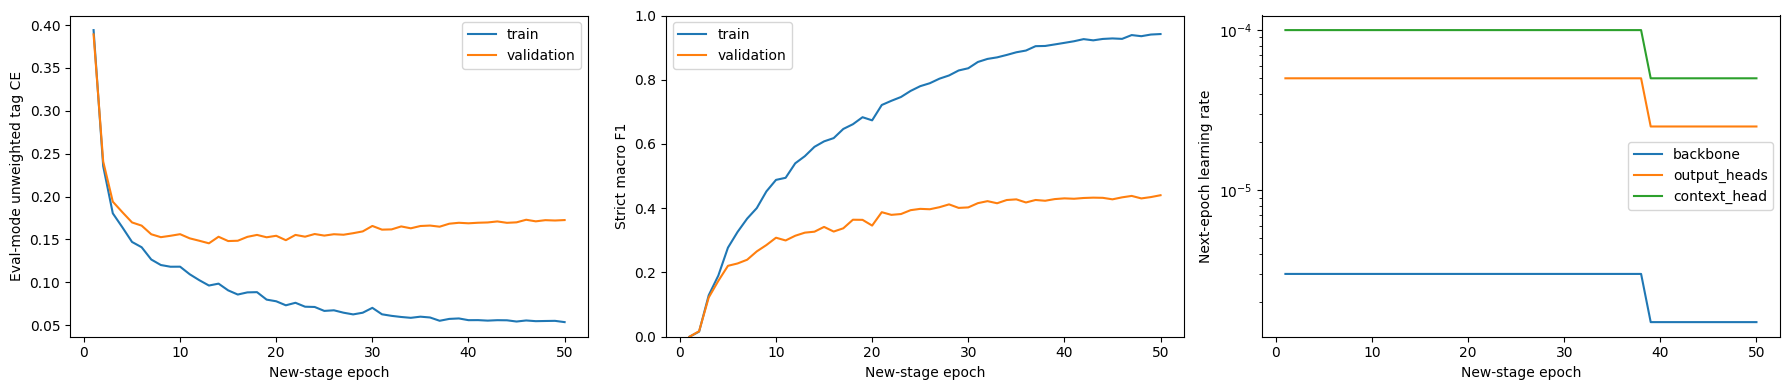

In [18]:
if not training_state["completed"]:
    print("Stage paused; the best checkpoint below is provisional. Save a backup to resume.")
best = torch.load(RUN_DIR / "best_ner.pt", map_location="cpu", weights_only=False)
assert best["protocol"] == protocol
base.load_state_dict(best["model_state"], strict=True)
best_epoch = best["epoch"]
del best
gc.collect()
val_predictions, val_losses, val_seconds = evaluate(model, documents, texts, val_windows,
    split["validation_ids"], tag_names, SETTINGS["prediction_batch_size"], device,
    True, SETTINGS["decode_mode"], SETTINGS["boundary_loss_weight"])
val_gold = {did: gold[did] for did in split["validation_ids"]}
best_metrics = official_evaluate(RUN_DIR, val_gold, val_predictions, labels,
    SRC / "evaluate_phase2.py", DATA_DIR / "Train/labels.txt", "best")
best_metrics["losses"] = val_losses
write_json(RUN_DIR / "best_validation_metrics.json", best_metrics)
summary, errors = span_errors(texts, val_gold, val_predictions)
write_json(RUN_DIR / "validation_error_analysis.json", summary)
write_json(RUN_DIR / "validation_error_samples.json", errors)
print("Run:", RUN_ID)
print("Best new-stage epoch:", best_epoch)
print("Strict macro F1:", best_metrics["strict_macro_f1"])
print("Previous best:", REFERENCE_STRICT_MACRO_F1)
print("Evaluation losses:", val_losses)
print("Label             Precision     Recall         F1    Gold")
for label, row in best_metrics["per_label"].items():
    print(f"{label:16s} {row['precision']:9.3f} {row['recall']:10.3f} {row['f1']:10.3f} "
          f"{row['true_positive']+row['false_negative']:7d}")
print("Span error analysis:", summary)
for error in errors[:10]:
    print(error["kind"], error["span"], repr(error["entity_text"]))

import matplotlib.pyplot as plt
history = read_json(RUN_DIR / "history.json")
checks = [r for r in history if r.get("kind") == "validation" and r["epoch"] > 0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
epochs = [r["epoch"] for r in checks]
for name in ("train", "validation"):
    axes[0].plot(epochs, [r[name+"_losses"]["unweighted_tag_loss"] for r in checks], label=name)
axes[0].set(xlabel="New-stage epoch", ylabel="Eval-mode unweighted tag CE")
axes[0].legend()
axes[1].plot(epochs, [r["train_strict_macro_f1"] for r in checks], label="train")
axes[1].plot(epochs, [r["strict_macro_f1"] for r in checks], label="validation")
axes[1].set(xlabel="New-stage epoch", ylabel="Strict macro F1", ylim=(0, 1))
axes[1].legend()
for kind in ("backbone", "output_heads", "context_head"):
    axes[2].plot(epochs, [r["learning_rates_next_epoch"][kind] for r in checks], label=kind)
axes[2].set(xlabel="New-stage epoch", ylabel="Next-epoch learning rate", yscale="log")
axes[2].legend()
fig.tight_layout()
fig.savefig(RUN_DIR / "training_curves.png", dpi=160)
plt.show()


## 8. CodaBench export

`GENERATE_TEST_PREDICTIONS` controls export from the best validation checkpoint. The ZIP
contains one root-level `prediction.json` with original-text offsets for every test ID.


In [19]:
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import display, FileLink

if GENERATE_TEST_PREDICTIONS:
    test_documents, _, test_audit = prepare_documents(test_texts, {}, tokenizer, labels)
    test_ids = sorted(test_texts)
    test_windows = make_windows(test_documents, test_ids, WINDOW_TOKENS, WINDOW_OVERLAP)
    test_predictions, test_seconds = predict(
        model, test_documents, test_texts, test_windows, test_ids, tag_names,
        SETTINGS["prediction_batch_size"], device, SETTINGS["decode_mode"])
    assert set(test_predictions) == set(test_texts)
    from evaluate_phase2 import spans as check_spans
    for did, entities in test_predictions.items():
        check_spans(entities, set(labels), f"prediction[{did}]")
        for a, b, label in entities:
            assert 0 <= a < b <= len(test_texts[did])
        if not test_texts[did]:
            assert entities == []
    prediction_path = RUN_DIR / "prediction.json"
    write_json(prediction_path, test_predictions)
    submission_path = Path("/kaggle/working") / f"{RUN_ID}_submission.zip"
    with ZipFile(submission_path, "w", ZIP_DEFLATED) as archive:
        archive.write(prediction_path, "prediction.json")
    with ZipFile(submission_path) as archive:
        assert archive.namelist() == ["prediction.json"]
        assert set(json.loads(archive.read("prediction.json"))) == set(test_texts)
    write_json(RUN_DIR / "test_prediction_summary.json", {
        "documents": len(test_predictions), "entities": sum(map(len, test_predictions.values())),
        "seconds": test_seconds, "empty_document_ids": [d for d in test_ids if not test_texts[d]],
    })
    print("Submission:", submission_path)
    display(FileLink(str(submission_path.relative_to(Path("/kaggle/working")))))


Submission: /kaggle/working/decoder_ner_bilstm_full_003_submission.zip


/kaggle/working/decoder_ner_bilstm_full_003_submission.zip

## 9. Diagnostic reports

The diagnostic archive contains training history, validation scores, the span-error
analysis and the run protocol.


In [20]:
from zipfile import ZipFile, ZIP_DEFLATED

diagnostic_path = Path("/kaggle/working") / f"{RUN_ID}_diagnostics.zip"
diagnostic_names = ["protocol.json", "run_summary.json", "history.json",
    "initial_validation_metrics.json", "best_validation_metrics.json",
    "best_validation_predictions.json", "validation_error_analysis.json",
    "validation_error_samples.json", "training_curves.png", "alignment_audit.json"]
with ZipFile(diagnostic_path, "w", ZIP_DEFLATED) as archive:
    for name in diagnostic_names:
        path = RUN_DIR / name
        if path.exists():
            archive.write(path, arcname=name)
print("Diagnostic ZIP:", diagnostic_path)
print("Run:", RUN_ID, "| best epoch:", best_epoch,
      "| strict macro F1:", best_metrics["strict_macro_f1"])
display(FileLink(str(diagnostic_path.relative_to(Path("/kaggle/working")))))


Diagnostic ZIP: /kaggle/working/decoder_ner_bilstm_full_003_diagnostics.zip
Run: decoder_ner_bilstm_full_003 | best epoch: 50 | strict macro F1: 0.44049594135847553


/kaggle/working/decoder_ner_bilstm_full_003_diagnostics.zip

## 10. Resume backup

The optional backup preserves the NER checkpoint, optimizer state, preparation metadata
and source files. Reattach the original Phase 1 run and tokenizer preparation when
resuming.


In [21]:
from zipfile import ZipFile, ZIP_STORED
from IPython.display import display, FileLink

if MAKE_RESUME_BACKUP:
    backup_path = Path("/kaggle/working") / f"{RUN_ID}_backup.zip"
    backup_tmp = backup_path.with_suffix(".zip.tmp")
    paths = [p for p in RUN_DIR.rglob("*") if p.is_file()
             and "__pycache__" not in p.parts and "parent_input" not in p.parts and not p.name.endswith(".tmp")]
    required_space = sum(p.stat().st_size for p in paths) + 256*2**20
    if shutil.disk_usage(ROOT).free < required_space:
        raise RuntimeError("Not enough free disk for a backup ZIP. Preserve the run folder as Kaggle output")
    with ZipFile(backup_tmp, "w", ZIP_STORED) as archive:
        for path in paths:
            archive.write(path, Path("runs") / RUN_ID / path.relative_to(RUN_DIR))
        archive.write(PREP_DIR / "tokenizer_state.pkl", "preparation/tokenizer_state.pkl")
        archive.write(PREP_DIR / "cache_manifest.json", "preparation/cache_manifest.json")
    backup_tmp.replace(backup_path)
    print("Resumable backup:", backup_path)
    print("Size:", round(backup_path.stat().st_size/2**30, 2), "GiB")
    display(FileLink(str(backup_path.relative_to(Path("/kaggle/working")))))


Resumable backup: /kaggle/working/decoder_ner_bilstm_full_003_backup.zip
Size: 3.32 GiB


/kaggle/working/decoder_ner_bilstm_full_003_backup.zip

## References

- The [official CS781 dataset](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone) supplies the Phase 2 L-NER folds. The embedded `evaluate_phase2.py` scores exact start offset, end offset and label matches, then averages F1 across the 12 entity labels.
- Lample et al. provided background for the bidirectional recurrent NER head. This run uses fixed BIO transitions for decoding. [Neural Architectures for Named Entity Recognition](https://aclanthology.org/N16-1030/)
- The training loss uses PyTorch's label smoothing and class weights. [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html)
